In [2]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
from PIL import Image
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 3
response_version = 1

stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [3]:

#Experiment column key:
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "strength", "target_on_left", "method", "catch_trial", "sample", "subject",  "rep", "mode", "stimtype"])
i=0
stimuli_root = "/export/raid1/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
gt_root = "/export/raid1/home/kneel027/data/umn-imagery/nsddata_stimuli/stimuli/imagery_images/"
method = "mirage_augmentations"
for sample in tqdm(range(18)):
    gt_sample = f"{sample}_ground_truth"
    gt_sample_path = f"{gt_root}/{sample}.png"
    gt_image = Image.open(gt_sample_path).resize((512,512))
    gt_image.save(f"stimuli_v{experiment_version}/{gt_sample}.png")
    
    if sample < 6:
        stimtype = "simple"
    elif sample < 12:
        stimtype = "complex"
    else:
        stimtype = "concept"
    for mode in ["vision", "imagery"]:
        for rep in range(10):
            # 1: Experiment 1, experiment to compare identification accuracy of recons with varying strength parameters with correct and incorrect VDVAE structural guidance
            for strength in np.round(np.arange(0.4, 1.05, 0.05), 2):
                for subj in [1, 2, 5, 7]:
                    
                    # Get random sample to compare against
                    if stimtype == "simple":
                        random_sample = random.choice([x for x in range(6) if x != sample])
                    elif stimtype == "complex":
                        random_sample = random.choice([x for x in range(6, 12) if x != sample])
                    else:
                        random_sample = random.choice([x for x in range(12, 18) if x != sample])
                    random_rep = random.choice([x for x in range(10)])
                    
                    correct_recon = f"{sample}_{rep}_subject{subj}_{mode}_{strength:.2f}"
                    incorrect_recon = f"{random_sample}_{random_rep}_subject{subj}_{mode}_{strength:.2f}"

                    # Load the stimulus images and save as pngs to stimuli folder
                    correct_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix/subject{subj}/{sample}/{rep}.png"
                    incorrect_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix/subject{subj}/{random_sample}/{random_rep}.png"
                    # Copy the stimulus images to the stimuli folder
                    # shutil.copy(correct_recon_path, f"stimuli_v{experiment_version}/{correct_recon}.png")
                    # shutil.copy(incorrect_recon_path, f"stimuli_v{experiment_version}/{incorrect_recon}.png")
                    # Configure stimuli names and order in experiment dataframe
                    order = random.randrange(2)
                    sample_names = [correct_recon, incorrect_recon]
                    left_sample = sample_names.pop(order)
                    right_sample = sample_names.pop()
                    
                    df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "strength" : strength, "target_on_left" : order == 0, "method" : method, "subject" : subj, "catch_trial" : None, "rep" : rep, "mode" : mode, "stimtype" : stimtype, "trial_rep" : 0}
                    i+=1
                
                # Ground truth calibration trials, not running for conceptual stimuli.
                if mode == "vision" and sample < 12:
                    # Get random sample to compare against
                    if stimtype == "simple":
                        random_sample = random.choice([x for x in range(6) if x != sample])
                    elif stimtype == "complex":
                        random_sample = random.choice([x for x in range(6, 12) if x != sample])
                    random_rep = random.choice([x for x in range(10)])
                    
                    correct_recon = f"{sample}_{rep}_gt_{strength}"
                    incorrect_recon = f"{random_sample}_{random_rep}_gt_{strength}"
                
                    # Load the stimulus images and save as pngs to stimuli folder
                    correct_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
                    incorrect_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{random_sample}/{random_rep}.png"
                    # Copy the stimulus images to the stimuli folder
                    # shutil.copy(correct_recon_path, f"stimuli_v{experiment_version}/{correct_recon}.png")
                    # shutil.copy(incorrect_recon_path, f"stimuli_v{experiment_version}/{incorrect_recon}.png")
                    # Configure stimuli names and order in experiment dataframe
                    order = random.randrange(2)
                    sample_names = [correct_recon, incorrect_recon]
                    left_sample = sample_names.pop(order)
                    right_sample = sample_names.pop()
                    
                    df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "strength" : strength, "target_on_left" : order == 0, "method" : method, "subject" : subj, "catch_trial" : None, "rep" : rep, "mode" : "gt", "stimtype" : stimtype, "trial_rep" : 0}
                    i+=1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


100%|██████████| 18/18 [03:39<00:00, 12.19s/it]

20280


In [4]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

4_4_subject7_imagery_0.55.png
0_9_subject7_imagery_0.55.png
2_6_subject1_vision_0.55.png
3_7_subject1_vision_0.55.png
6_0_subject5_imagery_0.95.png
11_0_subject5_imagery_0.95.png
8_5_subject1_vision_1.00.png
10_6_subject1_vision_1.00.png
17_7_subject1_vision_1.00.png
15_8_subject1_vision_1.00.png
12_9_subject2_imagery_0.70.png
13_4_subject2_imagery_0.70.png
9_9_subject7_imagery_0.90.png
10_1_subject7_imagery_0.90.png
1_6_subject5_imagery_0.70.png
2_7_subject5_imagery_0.70.png
9_6_gt_0.6.png
10_8_gt_0.6.png
4_3_gt_0.55.png
1_1_gt_0.55.png
12_2_subject7_imagery_0.40.png
14_6_subject7_imagery_0.40.png
7_5_gt_0.45.png
9_7_gt_0.45.png
9_6_subject1_imagery_0.90.png
10_5_subject1_imagery_0.90.png
17_2_subject5_imagery_0.55.png
16_8_subject5_imagery_0.55.png
9_2_subject2_imagery_0.45.png
8_6_subject2_imagery_0.45.png
16_9_subject7_imagery_0.40.png
15_6_subject7_imagery_0.40.png
14_9_subject2_imagery_0.85.png
17_8_subject2_imagery_0.85.png
5_8_subject5_imagery_0.95.png
1_8_subject5_imagery_0.95

### Add pID columns to assign trials to different participants

In [5]:
# Shuffle Experiment 1
df_exp1 = df_exp[df_exp['experiment'] == 1].sample(frac=1, random_state=42)
# Calculate the number of participants needed
exp1_trials_per_participant = 51
num_participants = len(df_exp1) // exp1_trials_per_participant

# Assign pID for Experiment 1
df_exp1['pID'] = [i % num_participants for i in range(len(df_exp1))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp1

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]
print(num_participants)

397


In [6]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    df_pid = df_exp_catch[(df_exp_catch['pID'] == pID)]
    # Ground truth catch trials
    try:
        gt_catch_trials = df_pid.sample(n=9)
    except:
        print(pID, df_pid)
    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        order = random.randrange(2)
        ground_truth = row['stim1']
        stims = [ground_truth, row['stim2']]
        
        gt_catch_trials.at[index, 'stim2'] = stims.pop(order)
        gt_catch_trials.at[index, 'stim3'] = stims.pop()
        # Target on left here means the ground truth repeat is on the left
        gt_catch_trials.at[index, 'target_on_left'] = (order == 0)
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
#shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'] == 1]))
# print(len(df_exp_catch[df_exp_catch['experiment'].isin([2, 3])]))

23853
61
397
23853


### Save experiment dataframe and tsv files

In [7]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)
df_catch_exp1 = df_exp_catch[df_exp_catch['experiment'] == 1]
# df_catch_exp2 = df_exp_catch[df_exp_catch['experiment'] == 2]

df_exp_tsv1 = df_catch_exp1[['pID', 'stim1', 'stim2', 'stim3']].copy()
# df_exp_tsv2 = df_catch_exp2[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv1.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1.tsv", sep="\t", index=False, header=False) 
# df_exp_tsv2.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp2.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [12]:
experiment_version = 2
response_version = 2
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [13]:

# Initialize a list to hold row dictionaries before creating the final dataframe
rows_list = []
df_2afc = df_responses[df_responses["task"] == "2AFC"]
# Parse trials in 2AFC experiment
for index, row in tqdm(df_2afc.iterrows()):
    if row['label'] == row['stim2_id']:
        picked_left = True
    elif row['label'] == row['stim3_id']:
        picked_left = False
    else:
        print("Error")
        break
    start_timestamp = row['time_trial_start']
    end_timestamp = row['time_trial_response']
    start = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))
    end = datetime.fromisoformat(end_timestamp.replace("Z", "+00:00"))
    # Calculate the difference in seconds
    response_time = (end - start).total_seconds()
    
    experiment_row = df_experiment[(df_experiment['stim1'] == row['stim1_name']) & (df_experiment['stim2'] == row['stim2_name']) & (df_experiment['stim3'] == row['stim3_name'])]
    if not experiment_row.empty:
        experiment_row = experiment_row.iloc[0]
        if experiment_row['target_on_left']:
            strength = experiment_row['stim2'].split("_")[-1]
        else:
            strength = experiment_row['stim3'].split("_")[-1]
        
        row_data = {
            **experiment_row.to_dict(),
            "strength" : strength,
            "picked_left": picked_left,
            "picked_target": picked_left == experiment_row['target_on_left'],
            "participant": row['participation'],
            "response_time": response_time,
        }
        
        rows_list.append(row_data)
    else:
        print(row['stim1_name'], row['stim2_name'], row['stim3_name'])

# Create the final dataframe from the list of row dictionaries
df_trial_combined = pd.DataFrame(rows_list)

# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

print(df_trial.head())

108it [00:00, 182.66it/s]

3_ground_truth 1_4_subject2_vision_0.65 3_ground_truth
3_ground_truth 1_4_subject2_vision_0.65 3_6_subject2_vision_0.70


496it [00:02, 211.69it/s]

13_ground_truth 13_5_subject5_imagery_0.90 14_2_subject5_imagery_0.95


815it [00:03, 205.48it/s]

15_ground_truth 14_4_subject5_imagery_0.55 15_0_subject5_imagery_0.60
15_ground_truth 14_4_subject5_imagery_0.55 15_ground_truth


1020it [00:04, 195.67it/s]

0_ground_truth 0_9_subject7_vision_0.95 1_1_subject7_vision_0.90


1148it [00:05, 192.08it/s]

17_ground_truth 17_3_subject7_vision_0.60 14_9_subject7_vision_0.55


1500it [00:07, 214.07it/s]

0_ground_truth 5_0_gt_0.55 0_9_gt_0.6


1650it [00:08, 209.01it/s]

2_ground_truth 2_7_subject7_vision_0.85 0_0_subject7_vision_0.75


1863it [00:09, 207.55it/s]

5_ground_truth 0_3_subject5_imagery_0.65 5_3_subject5_imagery_0.70


2166it [00:10, 208.59it/s]

0_ground_truth 1_3_subject7_imagery_0.65 0_6_subject7_imagery_0.70


2231it [00:10, 209.70it/s]

13_ground_truth 13_6_subject5_vision_0.80 15_9_subject5_vision_0.85


2273it [00:11, 188.41it/s]

2_ground_truth 1_5_subject7_imagery_0.65 2_8_subject7_imagery_0.70


2592it [00:12, 204.01it/s]

11_ground_truth 11_5_subject5_vision_0.80 10_0_subject5_vision_0.85


3350it [00:16, 202.51it/s]

15_ground_truth 15_3_subject5_imagery_0.60 16_2_subject5_imagery_0.55


3739it [00:18, 212.34it/s]

5_ground_truth 4_9_gt_0.85 5_1_gt_0.8
5_ground_truth 0_7_subject5_vision_0.60 5_5_subject5_vision_0.55


3937it [00:19, 211.11it/s]

17_ground_truth 17_5_subject2_imagery_0.45 16_7_subject2_imagery_0.50
13_ground_truth 15_1_subject2_vision_0.50 13_6_subject2_vision_0.45


4090it [00:19, 208.93it/s]

1_ground_truth 3_6_subject5_imagery_0.85 1_9_subject5_imagery_0.80
5_ground_truth 4_5_subject5_vision_0.85 5_9_subject5_vision_0.80


4216it [00:20, 201.71it/s]

6_ground_truth 6_8_subject1_vision_0.95 11_8_subject1_vision_0.90


4570it [00:22, 208.52it/s]

5_ground_truth 5_1_subject5_imagery_0.80 1_2_subject5_imagery_0.85


4760it [00:23, 208.01it/s]

0_ground_truth 0_3_subject2_imagery_0.85 3_3_subject2_imagery_0.80


4971it [00:24, 207.79it/s]

2_ground_truth 4_5_subject1_vision_0.45 2_4_subject1_vision_0.50
4_ground_truth 0_5_subject1_imagery_0.85 4_3_subject1_imagery_0.80


5663it [00:27, 213.20it/s]

8_ground_truth 7_3_subject2_imagery_0.60 8_2_subject2_imagery_0.55


5831it [00:28, 206.88it/s]

   pID  experiment            stim1                       stim2  \
0    1           1  13_ground_truth  14_5_subject1_imagery_0.60   
1    1           1   2_ground_truth                  2_3_gt_0.7   
2    1           1   2_ground_truth   3_8_subject1_imagery_0.95   
3    1           1   8_ground_truth   6_9_subject5_imagery_0.85   
4    1           1  14_ground_truth  13_8_subject2_imagery_0.80   

                        stim3 strength  target_on_left  \
0  13_8_subject1_imagery_0.60     0.60           False   
1                  4_5_gt_0.7      0.7            True   
2   2_9_subject1_imagery_0.95     0.95           False   
3   8_3_subject5_imagery_0.85     0.85           False   
4  14_0_subject2_imagery_0.80     0.80           False   

                        method catch_trial  sample  subject  rep     mode  \
0  braindiffuser_augmentations         NaN     NaN        1    8  imagery   
1  braindiffuser_augmentations         NaN     NaN        7    3       gt   
2  braindiffuser_

### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [15]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp1_missing = df_exp_missing[df_exp_missing['experiment'] == 1]
    df_catch_exp23_missing = df_exp_missing[df_exp_missing['experiment'].isin([2, 3])]


    df_exp_tsv1_missing = df_catch_exp1_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv23_missing = df_catch_exp23_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv1_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv23_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp23_missing.tsv", sep="\t", index=False, header=False) 

missing 2 pIDs
pID: 3 has 44 missing trials.
pID: 30 has 43 missing trials.


### Parse and remove participants that failed at least 2 catch trials

In [14]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

Total participants: 97
Participants to remove 1: []
Clean participants: 97
5804 5804
set()


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [29]:
experiment_version = 2
response_version = 2
dataframe_path = f"dataframes_v{experiment_version}/"
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')
filtered_df = filtered_df[filtered_df['stimtype'] == 'complex']


    strength     mode      mean       sem  picked_target_percentage  \
0       0.40       gt  1.000000  0.000000                100.000000   
1       0.40  imagery  0.769231  0.058997                 76.923077   
2       0.40   vision  0.870370  0.046139                 87.037037   
3       0.45       gt  0.923077  0.076923                 92.307692   
4       0.45  imagery  0.787234  0.060343                 78.723404   
5       0.45   vision  0.896552  0.040338                 89.655172   
6       0.50       gt  1.000000  0.000000                100.000000   
7       0.50  imagery  0.795918  0.058172                 79.591837   
8       0.50   vision  0.964286  0.025023                 96.428571   
9       0.55       gt  1.000000  0.000000                100.000000   
10      0.55  imagery  0.785714  0.049397                 78.571429   
11      0.55   vision  0.924242  0.032821                 92.424242   
12      0.60       gt  1.000000  0.000000                100.000000   
13    

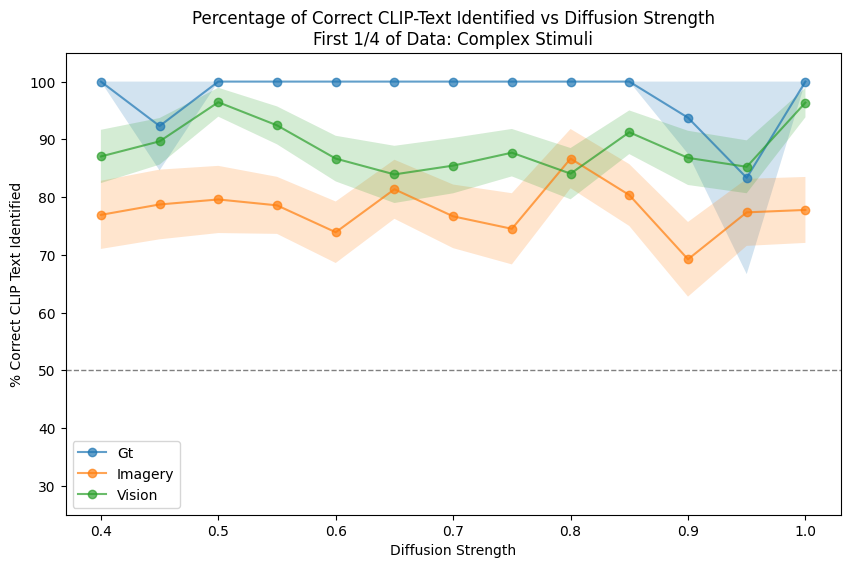

In [31]:
from scipy.stats import sem


# Group by 'strength' and calculate the mean and SEM of 'picked_target'
grouped_df = filtered_df.groupby(['strength', 'mode'])['picked_target'].agg(['mean', sem]).reset_index()

# Convert the mean to percentage
grouped_df['picked_target_percentage'] = grouped_df['mean'] * 100
grouped_df['sem_percentage'] = grouped_df['sem'] * 100

print(grouped_df)

# Create the plot
plt.figure(figsize=(10, 6))

# Plot lines for each unique mode
for mode in grouped_df['mode'].unique():
    mode_df = grouped_df[grouped_df['mode'] == mode]
    plt.plot(mode_df['strength'], 
             mode_df['picked_target_percentage'], 
             '-o', 
             label=mode.capitalize(), 
             alpha=0.7)

    # Fill the area between the lines
    plt.fill_between(mode_df['strength'], 
                     mode_df['picked_target_percentage'] - mode_df['sem_percentage'], 
                     mode_df['picked_target_percentage'] + mode_df['sem_percentage'], 
                     alpha=0.2)

# Adding labels and title
plt.xlabel('Diffusion Strength')
plt.ylabel('% Correct CLIP Text Identified')
# Set the y-axis limits
plt.axhline(y=50, color='gray', linestyle='--', linewidth=1)
plt.ylim(25, 105)
plt.title('Percentage of Correct CLIP-Text Identified vs Diffusion Strength\nFirst 1/4 of Data: Complex Stimuli')
plt.legend()

# Show the plot
plt.show()

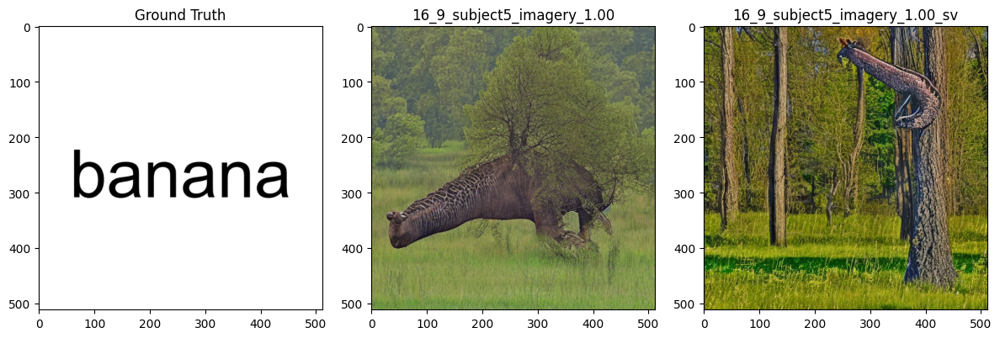

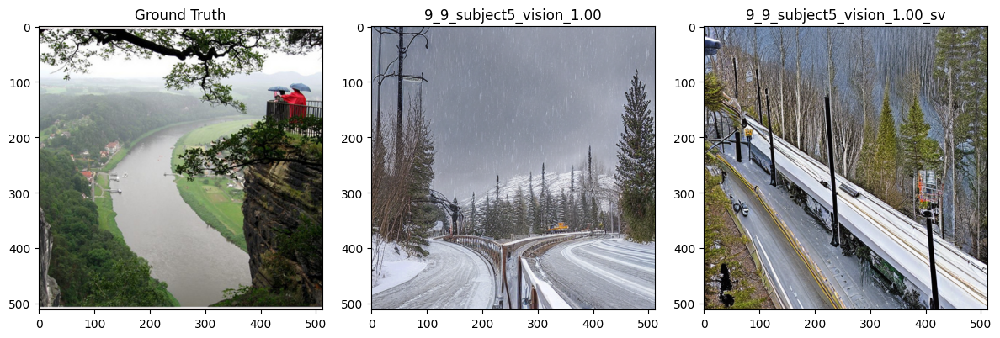

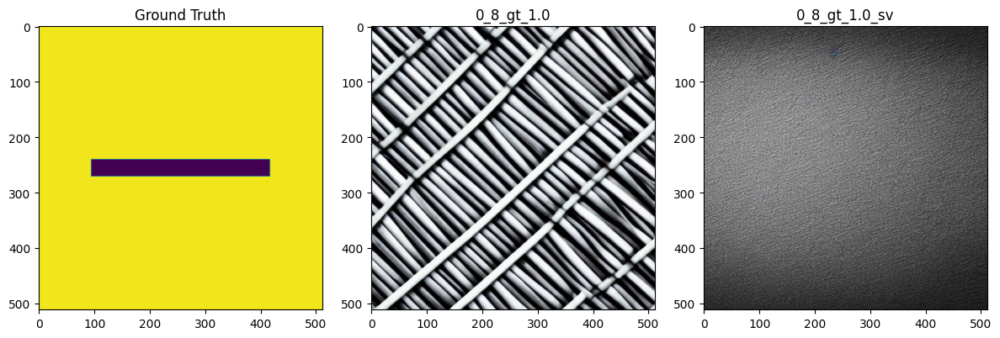

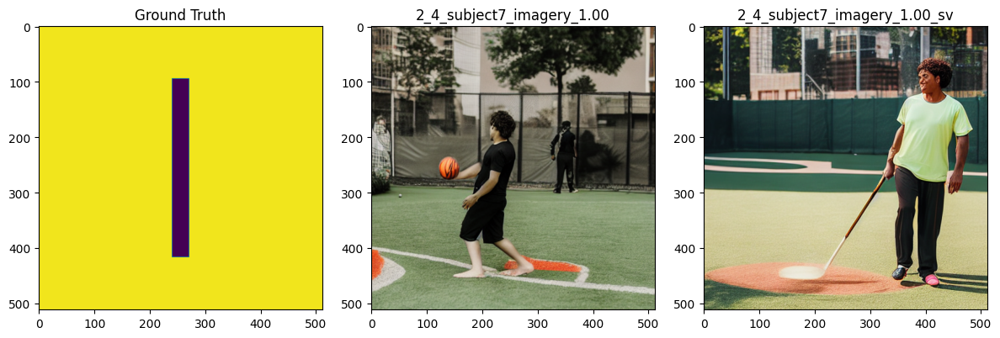

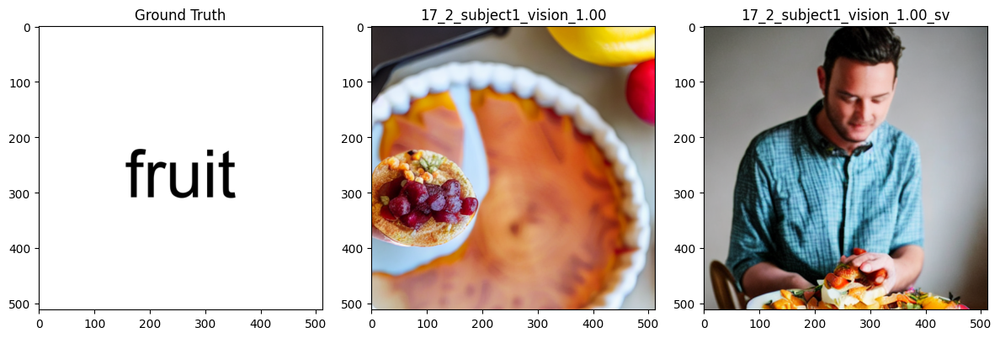

...

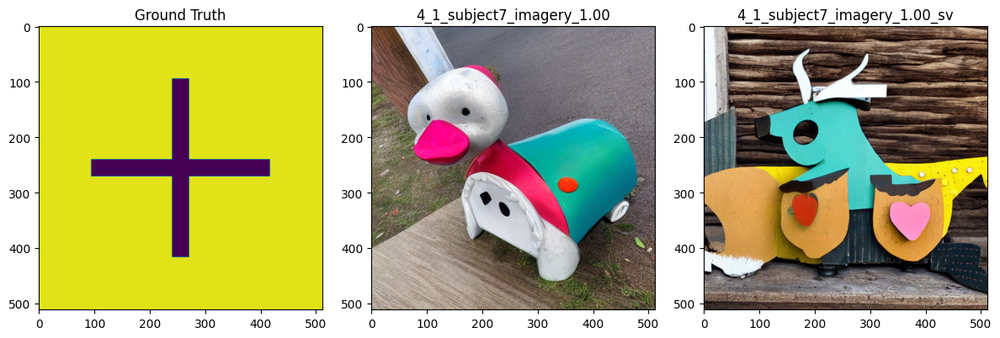

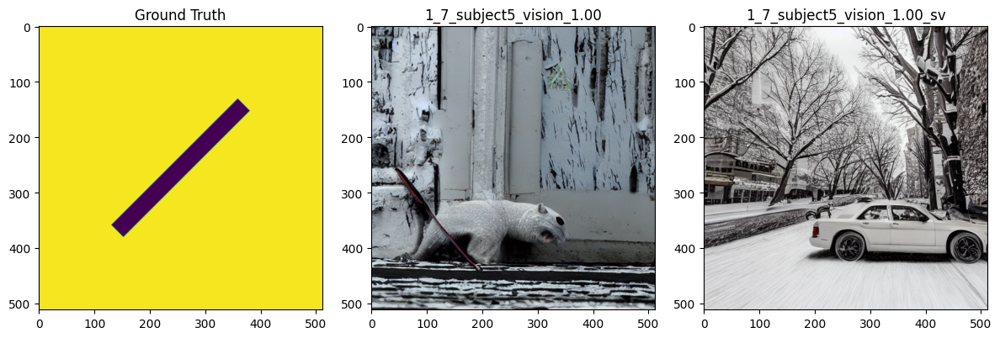

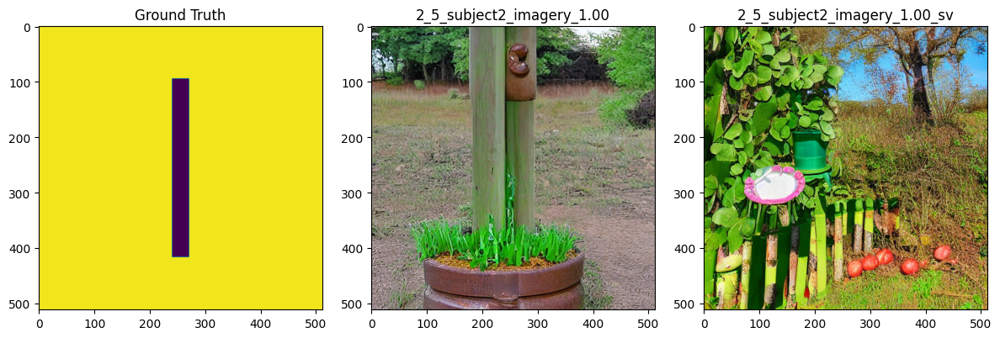

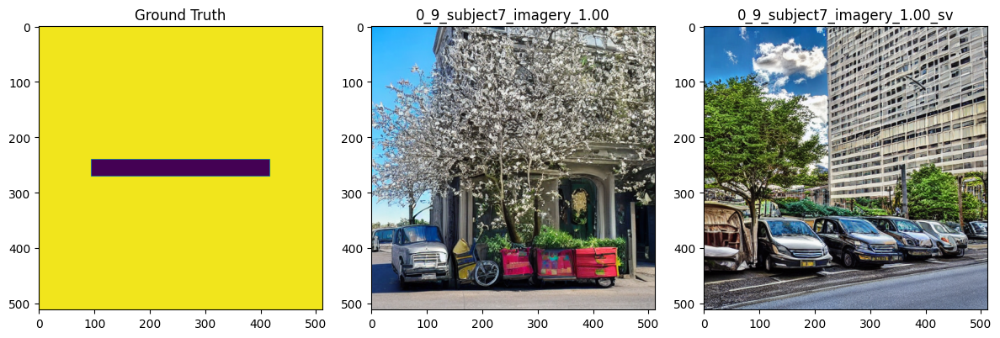

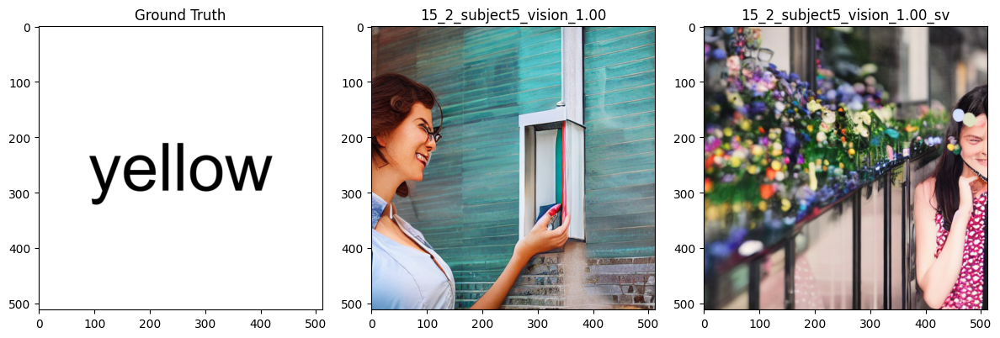

In [30]:

strength1 = filtered_df[filtered_df['strength'] == 1.0]
strength1.head()

# Iterate over the first 20 rows of strength1 dataframe
for i, (_, row) in enumerate(strength1.iterrows()):
    gt = row['stim1']
    stims = [row['stim2'], row['stim3']]
    if not row['target_on_left']:
        stims.reverse()
    
    # Create a 1x3 grid of subplots
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    # Plot the ground truth
    axs[0].imshow(Image.open(f"stimuli_v1/{gt}.png"))
    axs[0].set_title('Ground Truth')

    # Plot the stimuli
    for j, stim in enumerate(stims):
        axs[j + 1].imshow(Image.open(f"stimuli_v1/{stim}.png"))
        axs[j + 1].set_title(stim)

    # Adjust the spacing between subplots
    plt.tight_layout()

    # Display the plot
    plt.show()

    if i == 19:
        break

In [11]:

# Iterate over each experiment
experiment = 1
for mode in ["vision", "imagery"]:
    
    print(f"Mode: {mode}")
    for stimtype in ["simple", "complex"]:
        print(f"Stimtype: {stimtype}")
        # Filter the data for the current method, mode, and experiment
        df_trial_exp1 = df_trial_exp[(df_trial_exp['method'] != "takagi") & (df_trial_exp['method'] != "mindeye2") & (df_trial_exp['experiment'] == experiment) & (df_trial_exp['mode'] == mode) & (df_trial_exp['stimtype'] == stimtype)]
        # Perform a binomial test
        # The null hypothesis is that the probability of success is 0.5 (chance level)
        p_value = binomtest(df_trial_exp1['picked_target'].sum(), n=len(df_trial_exp1['picked_target']), p=0.5, alternative='two-sided').pvalue

        print("Number of experiment trials:", len(df_trial_exp1))
        print("Success rate: ", len(df_trial_exp1[df_trial_exp1["picked_target"]]) / len(df_trial_exp1))
        print(f'P-value: {p_value}')
        
        print("--------------------")
        print()


Mode: vision
Stimtype: simple
Number of experiment trials: 1180
Success rate:  0.7254237288135593
P-value: 8.186063399887696e-56
--------------------

Stimtype: complex
Number of experiment trials: 1185
Success rate:  0.8286919831223629
P-value: 7.073258575680375e-123
--------------------

Mode: imagery
Stimtype: simple
Number of experiment trials: 1185
Success rate:  0.6649789029535865
P-value: 2.795007020162622e-30
--------------------

Stimtype: complex
Number of experiment trials: 1190
Success rate:  0.7352941176470589
P-value: 2.3051714461153325e-61
--------------------

